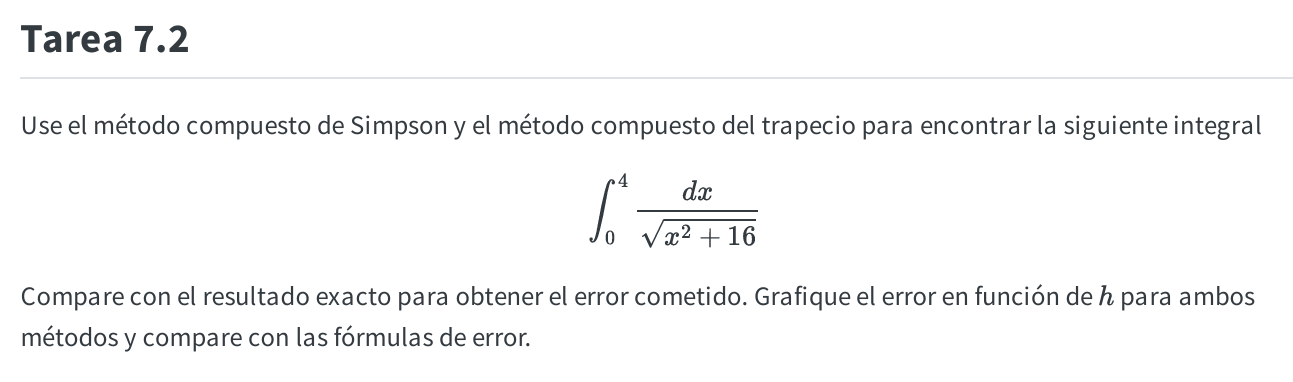

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#definimos la funcion
def f(x):
    return 1/np.sqrt(x**2 + 16)


#definimos los límites de integración
a = 0
b = 4

I_exacto = np.log(1 + np.sqrt(2)) #Para calcular el
                                  #valor exacto de la integral

print("Valor exacto de la integral:", I_exacto)

Valor exacto de la integral: 0.8813735870195429


### **Método compuesto del trapecio**

La fórmula del método compuesto del trapecio es:

$$T_n = \frac{h}{2} \left[ f(a) + 2 \sum_{i=1}^{n-1} f(x_i) + f(b) \right]$$

Donde:

$$h = \frac{b - a}{n}$$

En este método dividimos el intervalo en varios trapecios pequeños y sumamos sus áreas

In [4]:
#se crea una función para aplicar el método del trapecio

def trapecio(f, a, b, n):

    #calculamos el ancho de cada intervalo
    h = (b-a)/n

    #creamos los puntos entre a y b
    x = np.linspace(a, b, n+1)

    #evaluamos la función en los puntos interiores
    fx = f(x[1:-1])

    #aplicamos la fórmula compuesta del trapecio
    resultado = (h/2)*(f(a) + 2*np.sum(fx) + f(b))

    return resultado

#y se prueba el método del trapecio con 4 intervalos

resultado_trapecio = trapecio(f, a, b, 4)

print("Resultado del trapecio:", resultado_trapecio)

Resultado del trapecio: 0.8795307704346305


### **Método compuesto de Simpson**

Fórmula compuesta de Simpson es:

$$S_n = \frac{h}{3} \left[ f(a) + 4 \sum f(x_{2i-1}) + 2 \sum f(x_{2i}) + f(b) \right]$$

Necesitamos que el número de intervalos sea par, la diferencia con el trapecio es que Simpson utiliza polinomios cuadráticos para aproximar la función, consiguiendo una mayor precisión

In [5]:
#función para aplicar simpson compuesto

def simpson(f, a, b, n):

    # Simpson necesita una cantidad par de intervalos
    if n % 2 != 0:
        print("El numero de intervalos debe ser par")
        return None

    #ancho de los intervalos
    h = (b-a)/n

    #los puntos de integración
    x = np.linspace(a, b, n+1)

    #sumamos los puntos que tienen coeficiente 4
    suma_impares = np.sum(f(x[1:-1:2]))

    #sumamos los puntos que tienen coeficiente 2
    suma_pares = np.sum(f(x[2:-1:2]))

    #y aplicamos la fórmula de Simpson
    resultado = (h/3)*(f(a) + 4*suma_impares + 2*suma_pares + f(b))

    return resultado

#caalculamos la integral usando Simpson con 4 intervalos

resultado_simpson = simpson(f, a, b, 4)

print("Resultado de Simpson:", resultado_simpson)

Resultado de Simpson: 0.8813775969806423


Para comparar los métodos calculamos el error absoluto:

Error = | I_exacto - I_aproximado |

In [7]:
#se calcula el error de cada metodo

error_trapecio = abs(I_exacto - resultado_trapecio)

error_simpson = abs(I_exacto - resultado_simpson)


#printeamos los resultados

print("Valor exacto:", I_exacto)

print("Resultado del trapecio:", resultado_trapecio)
print("Error del trapecio:", error_trapecio)

print("")

print("Resultado de Simpson:", resultado_simpson)
print("Error de Simpson:", error_simpson)

Valor exacto: 0.8813735870195429
Resultado del trapecio: 0.8795307704346305
Error del trapecio: 0.0018428165849124767

Resultado de Simpson: 0.8813775969806423
Error de Simpson: 4.009961099393777e-06


Simpson obtiene un resultado mucho más cercano al valor exacto que el método del trapecio

### **Calcular el error para distintos valores de h**

Para hacerlo tenemos que probar diferentes cantidades de intervalos:

\[
n = 2, 4, 8, 16, 32, 64, 128
\]

Recordemos que:

$$  h = \frac{4}{n} $$

Mientras más intervalos utilizamos, menor será el tamaño de cada uno y  obtendremos una aproximación más precisa

In [9]:
intervalos = [2, 4, 8, 16, 32, 64, 128]

#se crean listas vacías para guardar los resultados

valores_h = []
errores_trapecio = []
errores_simpson = []


# Repetimos los cálculos para cada cantidad de intervalos

for n in intervalos:

    #calc. el tamaño del intervalo
    h = (b-a)/n

    #calculamos los resultados de ambos métodos
    T = trapecio(f, a, b, n)
    S = simpson(f, a, b, n)

    #errores absolutos
    error_T = abs(I_exacto - T)
    error_S = abs(I_exacto - S)

    #y Guardamos los resultados
    valores_h.append(h)
    errores_trapecio.append(error_T)
    errores_simpson.append(error_S)


#se muestra unatabla con los resultados

print("       h          Error Trapecio       Error Simpson")

for i in range(len(valores_h)):

    print(valores_h[i], "   ",
          errores_trapecio[i], "   ",
          errores_simpson[i])

       h          Error Trapecio       Error Simpson
2.0     0.007383296222948199     0.0005709961551745302
1.0     0.0018428165849124767     4.009961099393777e-06
0.5     0.00046044517789289863     3.4529111347936237e-07
0.25     0.00011509460279945927     2.225556516854965e-08
0.125     2.8772599633519746e-05     1.4014218674418544e-09
0.0625     7.1930840942480145e-06     8.775180582176745e-11
0.03125     1.798266908048518e-06     5.487166276907374e-12


A medida que disminuye \(h\), también disminuyen los errores de ambos métodos

### Gráfico del error en función de h

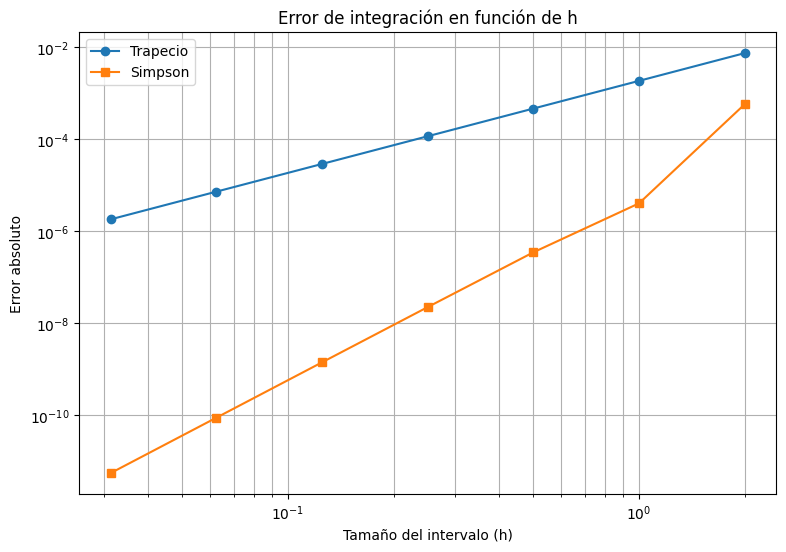

In [10]:
#graficamos los errores de ambos métodos

plt.figure(figsize=(9,6))

#error del método del trapecio
plt.loglog(valores_h, errores_trapecio, 'o-', label="Trapecio")

#error del método de Simpson
plt.loglog(valores_h, errores_simpson, 's-', label="Simpson")

plt.title("Error de integración en función de h")
plt.xlabel("Tamaño del intervalo (h)")
plt.ylabel("Error absoluto")
plt.legend()
plt.grid(True, which="both")

plt.show()

Vemos que

* La curva del trapecio disminuye a medida que disminuye \(h\)
* La curva de Simpson también disminuye, pero más rápido
* Ambos métodos mejoran la predicción al aumentar la cantidad de intervalos

### Comparación con las fórmulas de error de los apuntes


Error del método compuesto del trapecio:

$$E_T = \frac{h^2(b - a)}{12} f''(\mu)$$

Error del método compuesto de Simpson:

$$E_S = \frac{h^4(b - a)}{180} f^{(4)}(\mu)$$

Donde \(mu\) es un punto que se encuentra dentro del intervalo de integración

Lo importante es observar las potencias de \(h\):

* Trapecio: el error es proporcional a \(h^2\)
* Simpson: el error es proporcional a \(h^4\)

Esto significa que al reducir el tamaño del intervalo a la mitad:

* El error del trapecio debería reducirse aproximadamente 4 veces.
* El error de Simpson debería reducirse aproximadamente 16 veces.

In [13]:
#como disminuye el error cuando reducimos h

print("Comparacion de los errores")
print("")

for i in range(len(valores_h)-1):

    #se calcula cuantas veces disminuye el error
    reduccion_T = errores_trapecio[i] / errores_trapecio[i+1]

    reduccion_S = errores_simpson[i] / errores_simpson[i+1]

    print("Para h =", valores_h[i])

    print("Reduccion del error del trapecio:", reduccion_T)

    print("Reduccion del error de Simpson:", reduccion_S)

    print("")

Comparacion de los errores

Para h = 2.0
Reduccion del error del trapecio: 4.006527987319402
Reduccion del error de Simpson: 142.3944375073496

Para h = 1.0
Reduccion del error del trapecio: 4.0022497213362564
Reduccion del error de Simpson: 11.613276284428466

Para h = 0.5
Reduccion del error del trapecio: 4.0005801027453725
Reduccion del error de Simpson: 15.514821163351488

Para h = 0.25
Reduccion del error del trapecio: 4.000146120456053
Reduccion del error de Simpson: 15.880703509482696

Para h = 0.125
Reduccion del error del trapecio: 4.0000365985610955
Reduccion del error de Simpson: 15.970290916728029

Para h = 0.0625
Reduccion del error del trapecio: 4.000009154399644
Reduccion del error de Simpson: 15.992190029135642



**Podemos decir después de todo que el método compuesto de Simpson es más preciso para este ejercicio, ya que su error disminuye más rápidamente al aumentar la cantidad de intervalos**

## Nota: 7.0

Base: 1/1; funcionamiento: 4/4; comentarios: 1/1; claridad: 1/1.
